✅  Imports done.
2-D dataset  : (600, 2)   true clusters = 5
High-D dataset: (500, 10)  true clusters = 4
✅  Models fitted on 2-D data for K = [2, 3, 4, 5, 6, 7, 8]
✅  Models fitted on High-D data for K = [2, 3, 4, 5, 6, 7, 8]


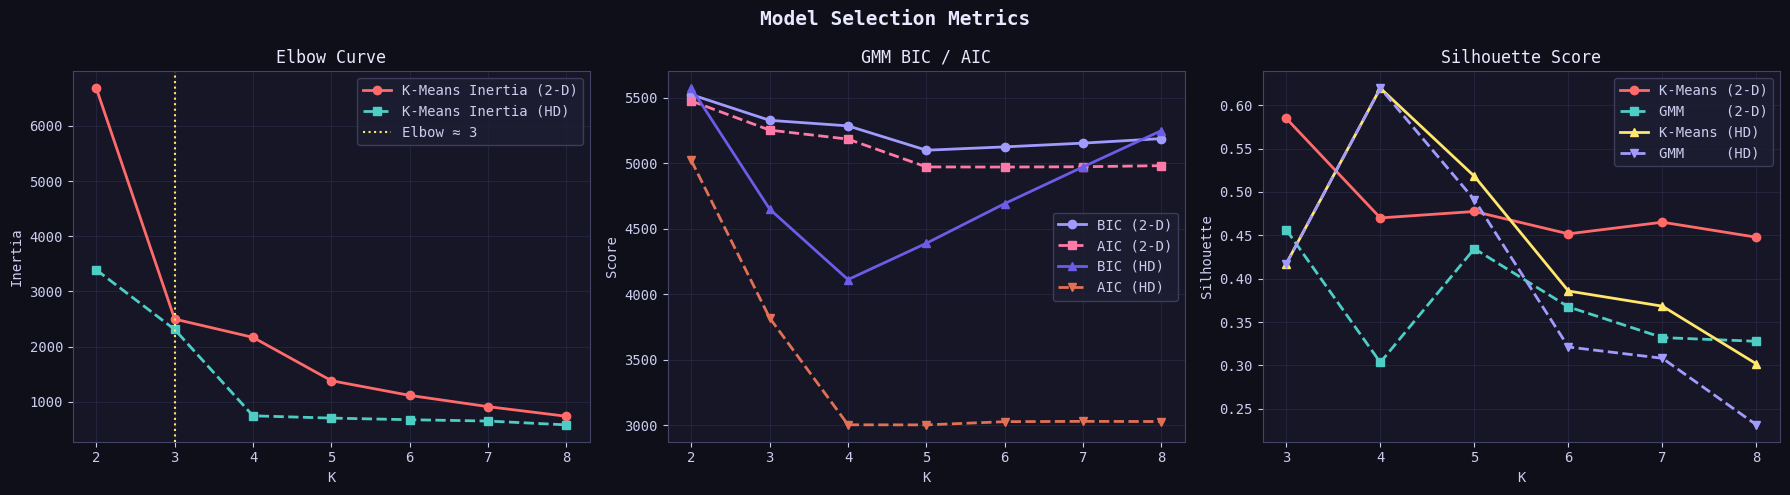

✅  Plot 1 saved.


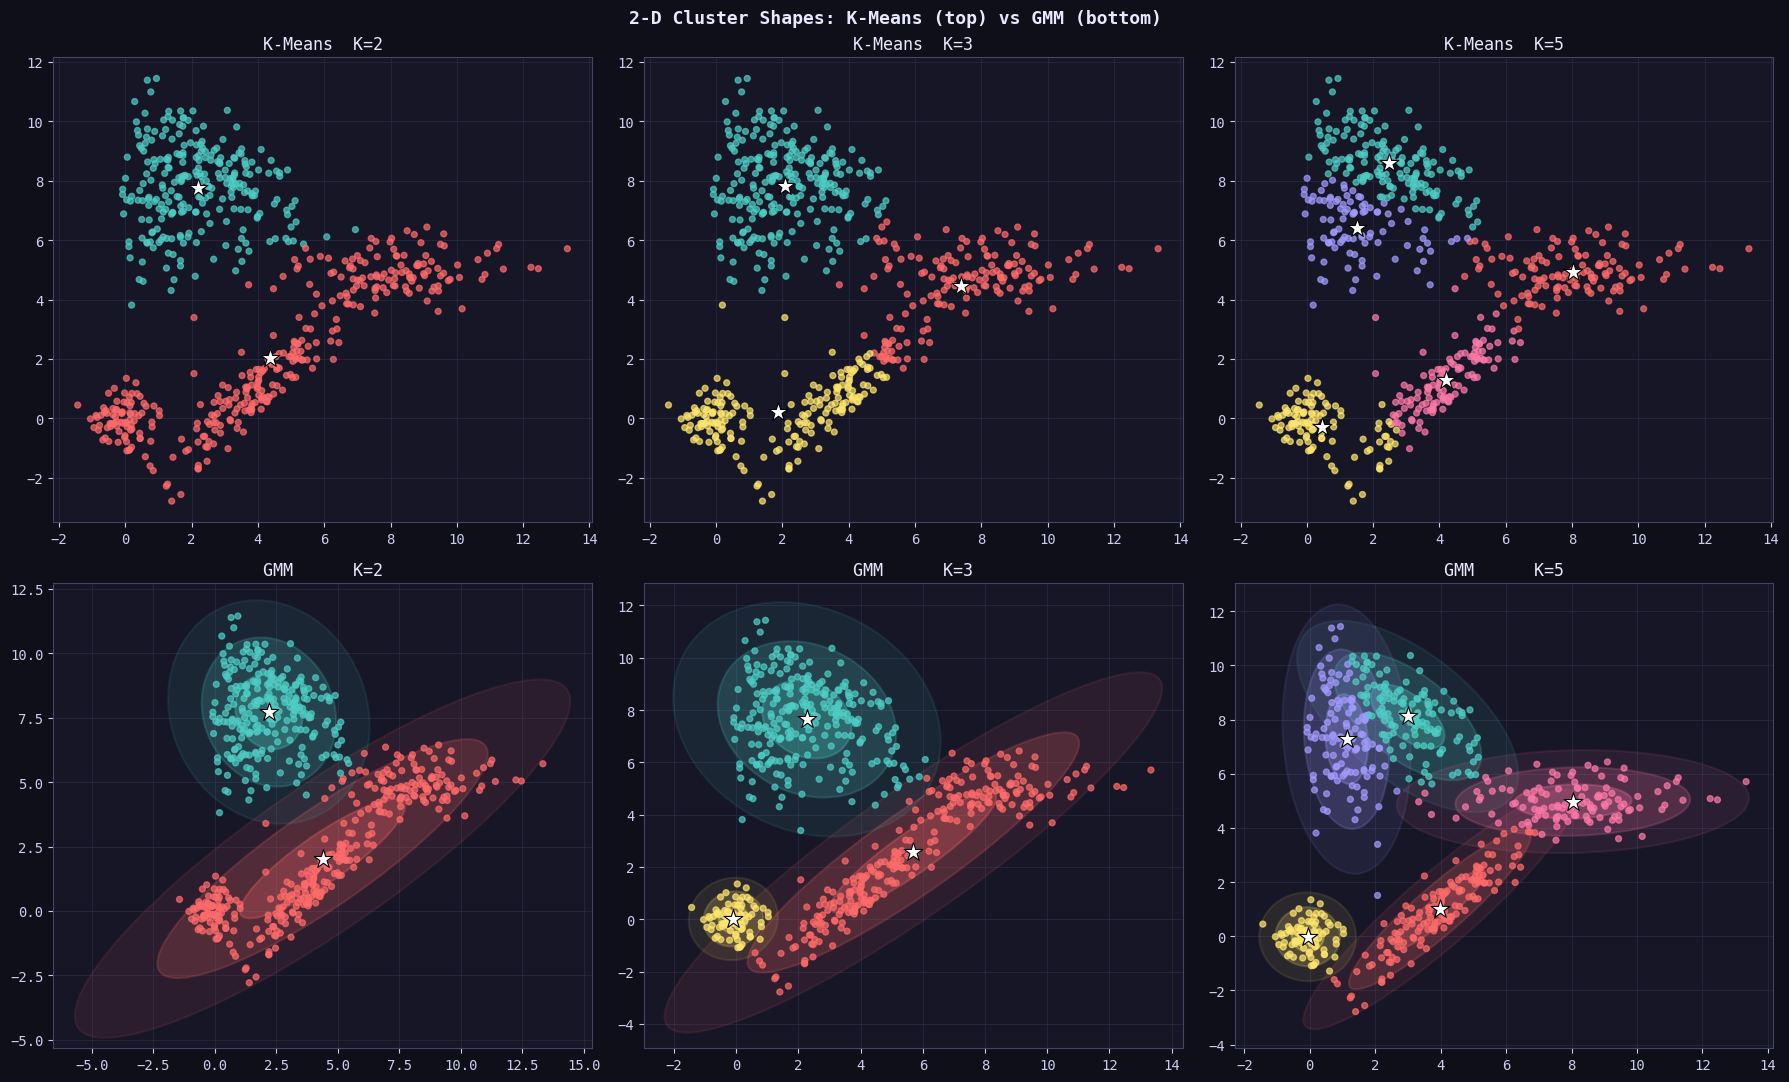

✅  Plot 2 saved.


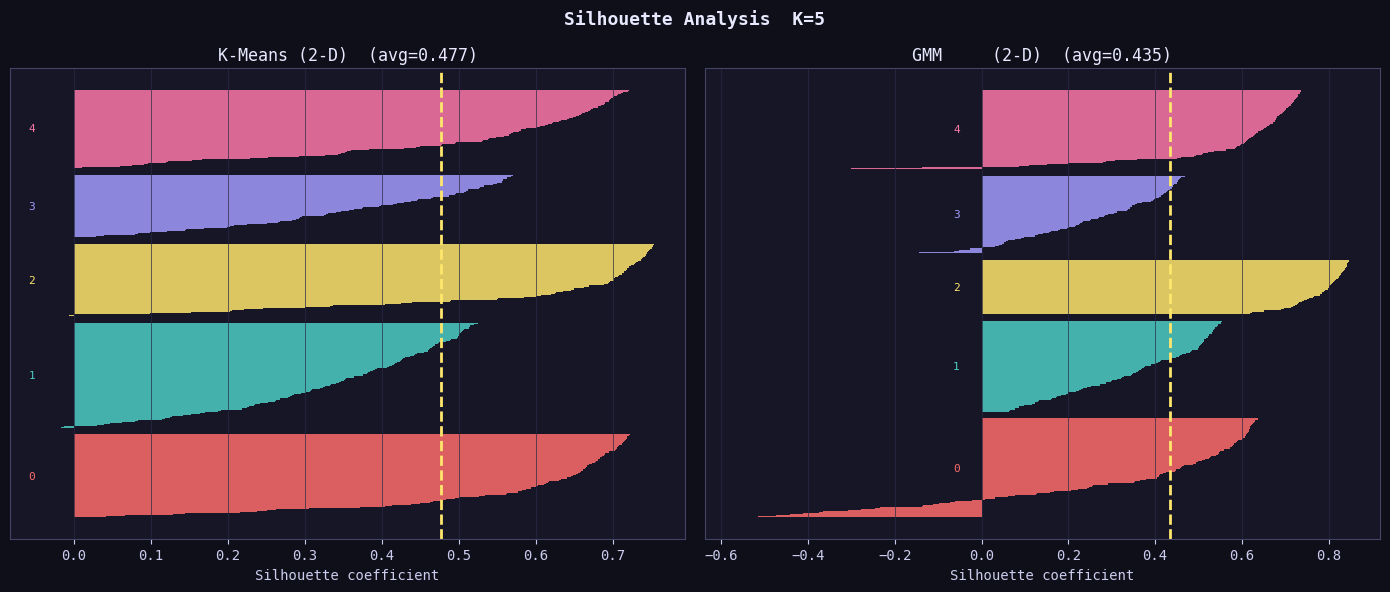

✅  Plot 3 saved.


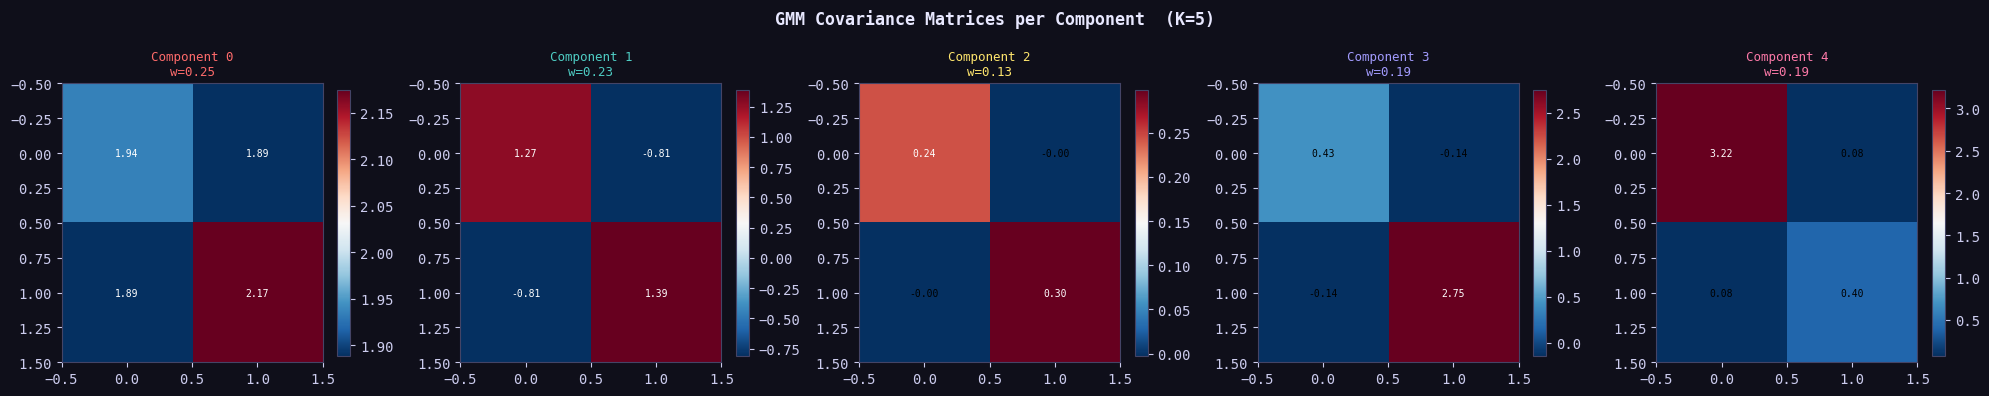

✅  Plot 4 saved.


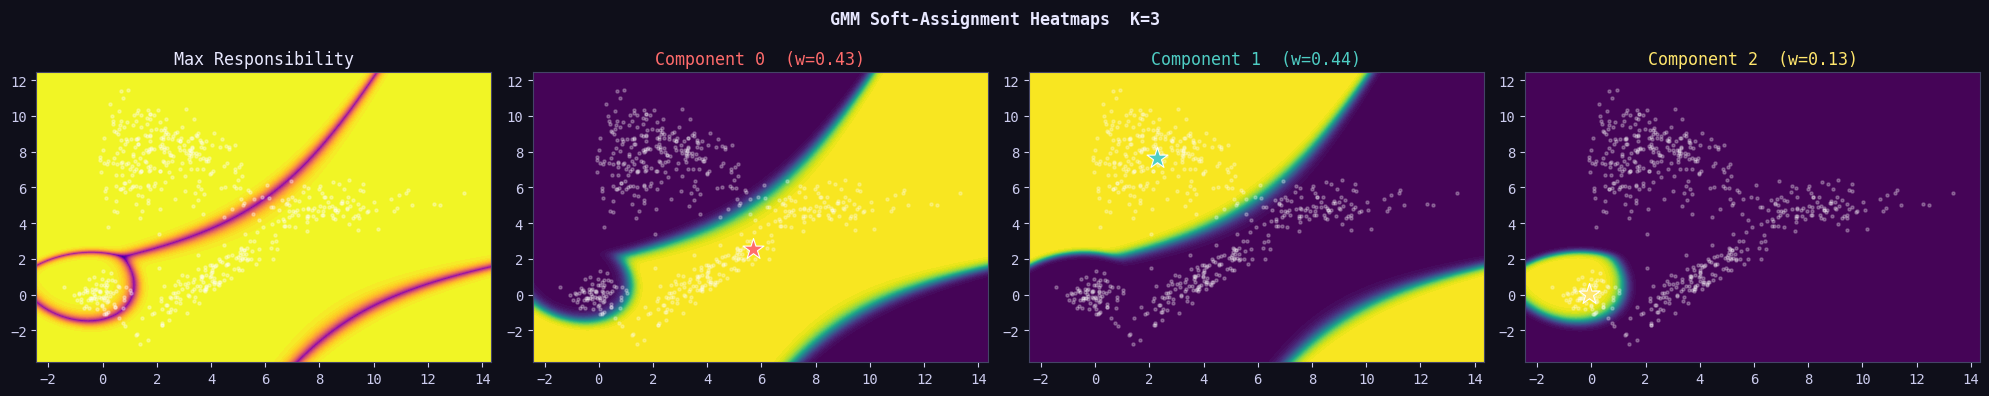

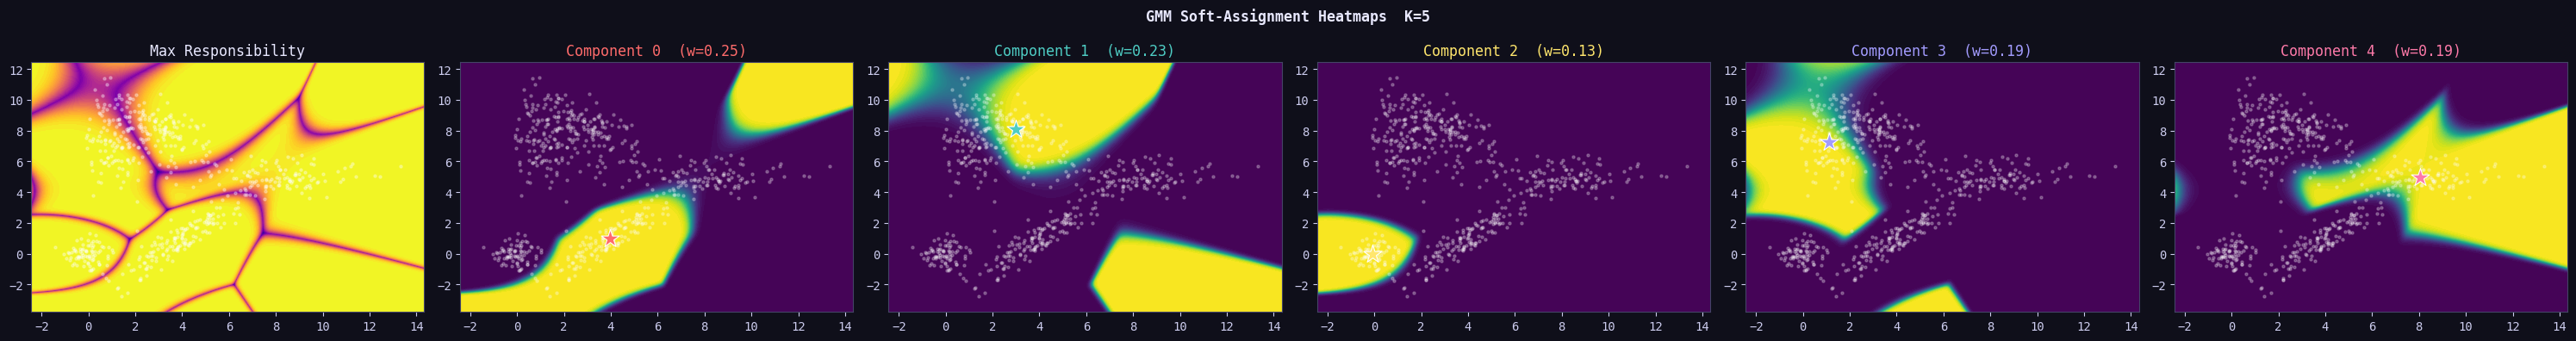

✅  Plot 5 saved.


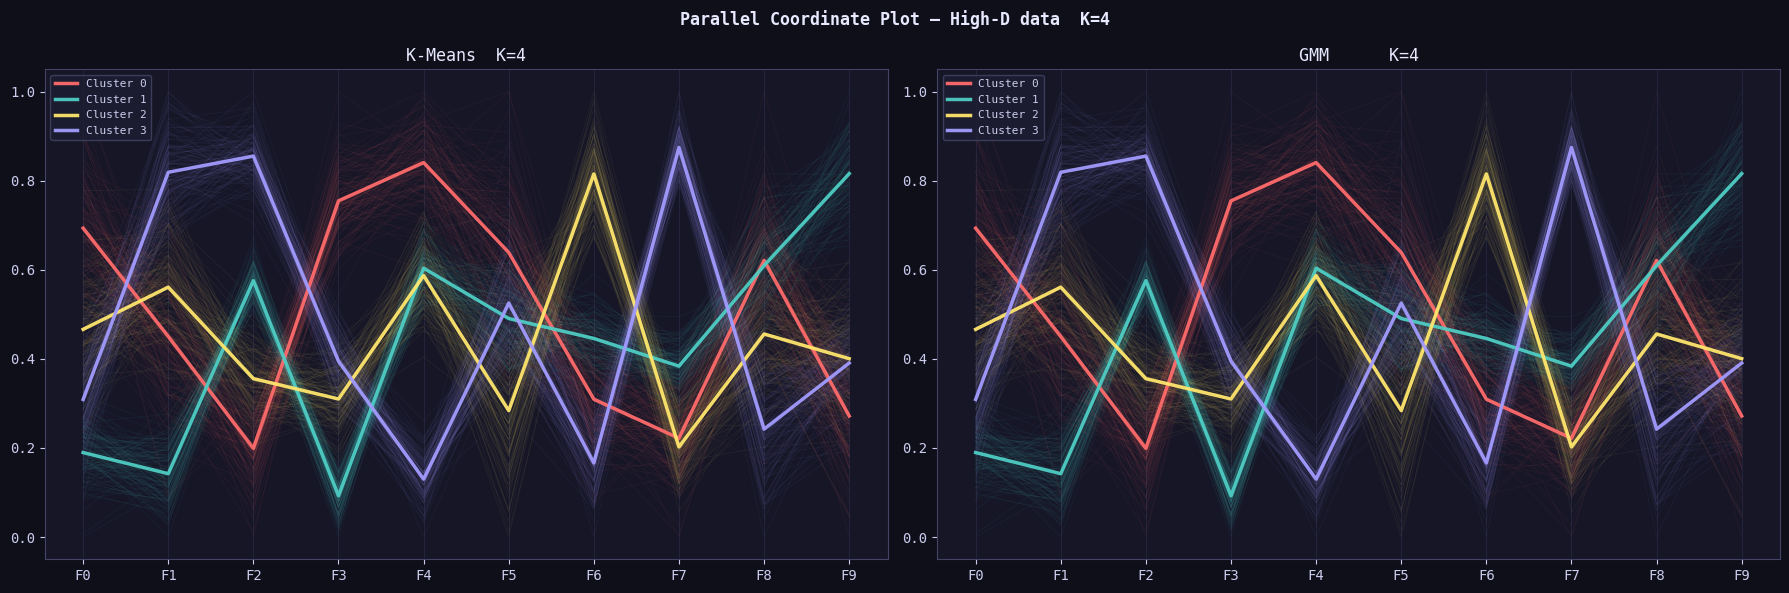

✅  Plot 6 saved.


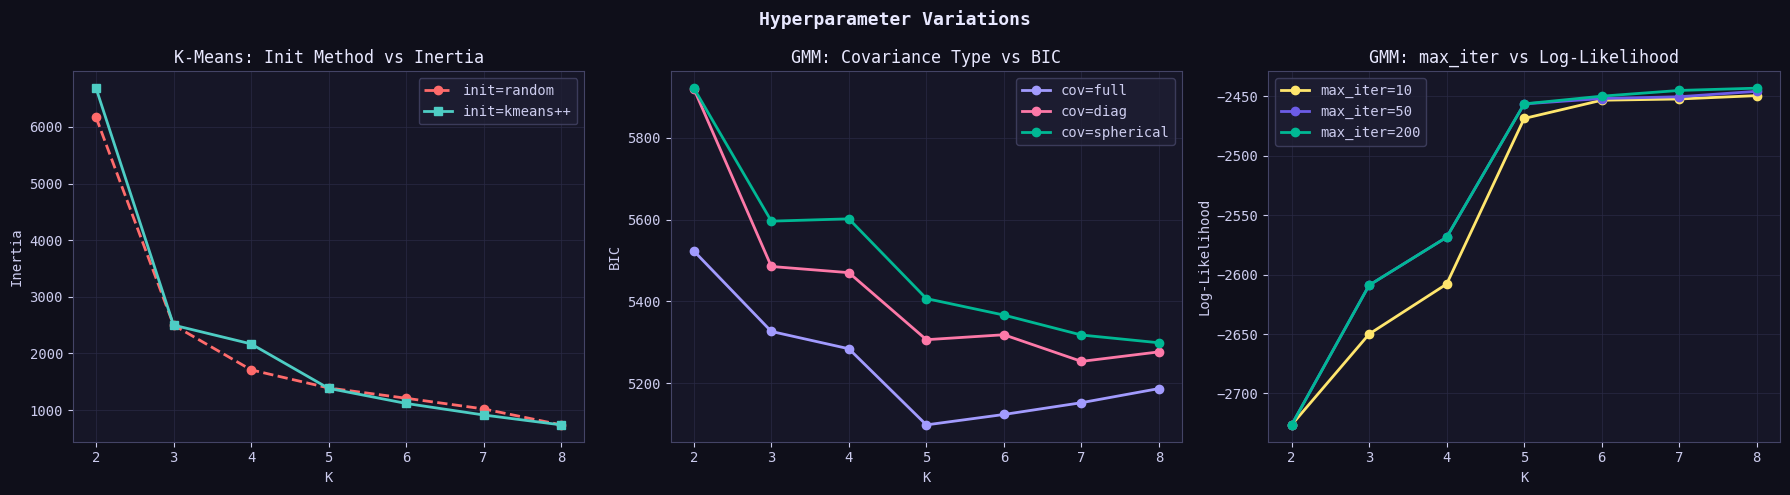

✅  Plot 7 saved.


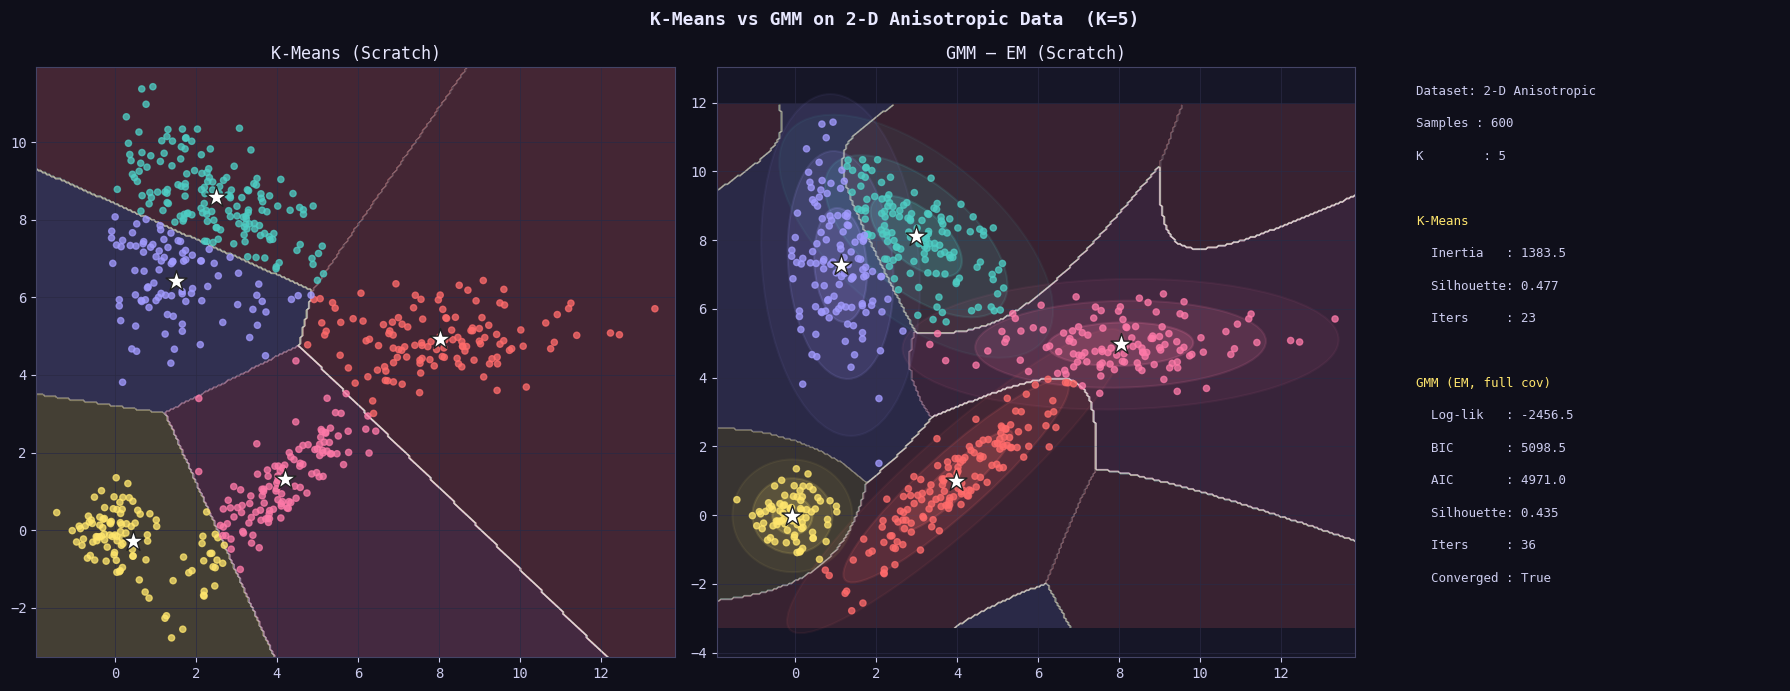

✅  Plot 8 saved.


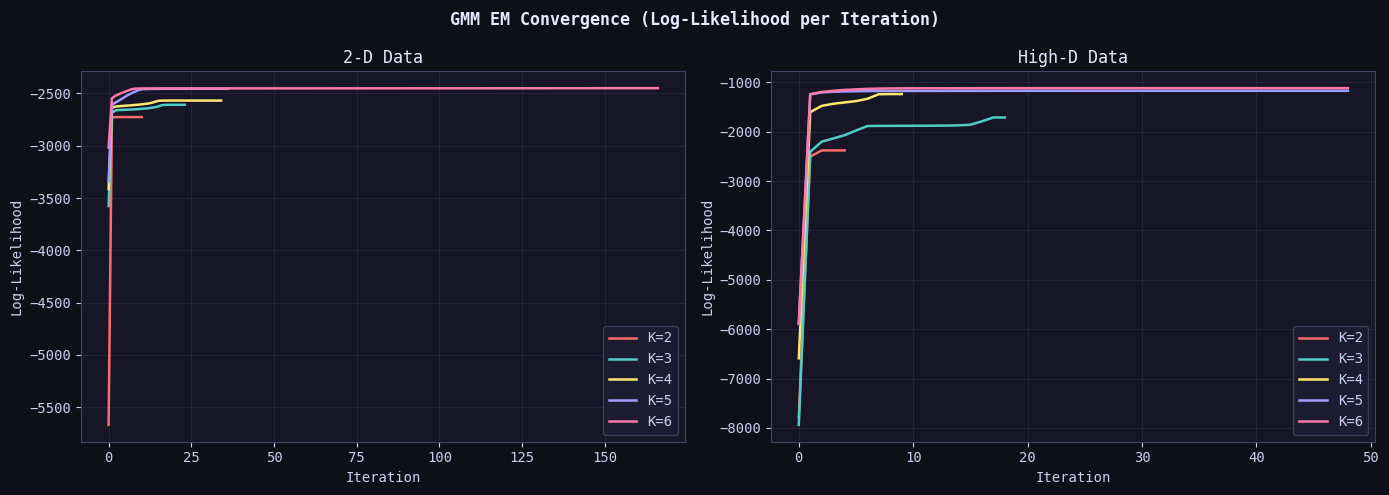

✅  Plot 9 saved.


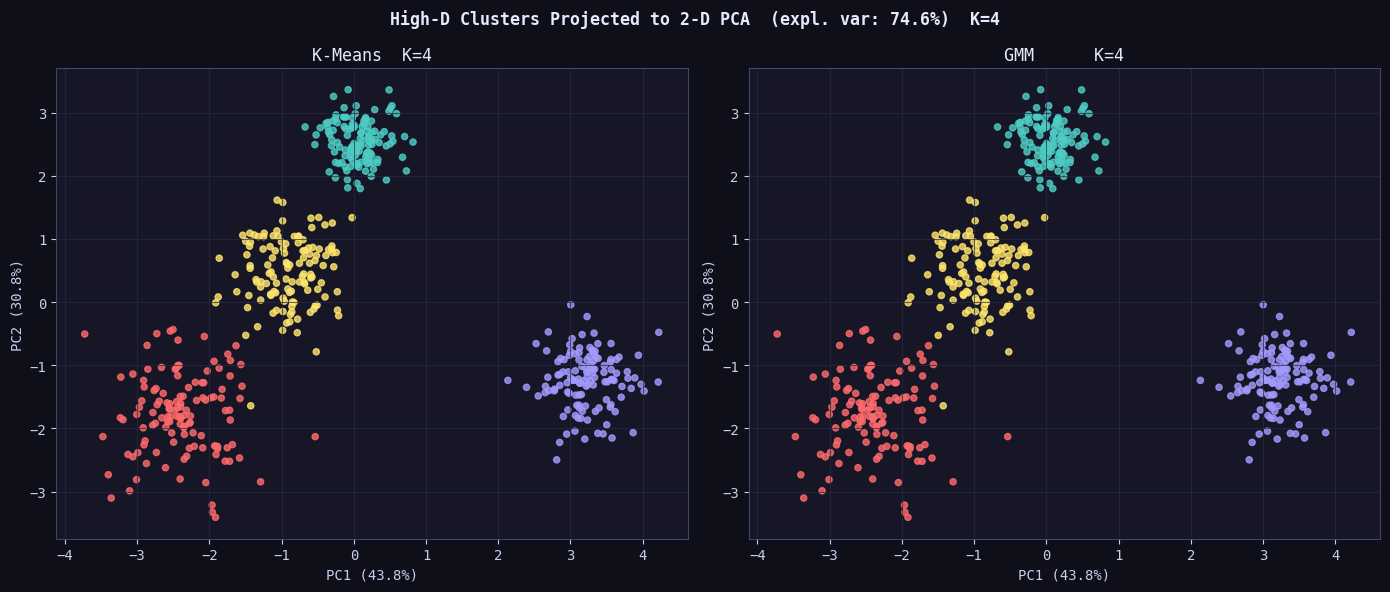

✅  Plot 10 saved.

── Sklearn Sanity Check ─────────────────────────────
Scratch KMeans inertia : 1383.49
Sklearn KMeans inertia : 1385.31
Scratch GMM log-lik    : -2456.52
Sklearn GMM log-lik    : -2457.79
Scratch KMeans sil     : 0.4775
Sklearn KMeans sil     : 0.4649
✅  Sanity check done. All plots saved to working directory.


In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
from matplotlib.colors import ListedColormap
from matplotlib.gridspec import GridSpec
import matplotlib.cm as cm
import warnings
warnings.filterwarnings("ignore")

from scipy.stats import multivariate_normal
from scipy.spatial.distance import cdist
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans as SK_KMeans
from sklearn.mixture  import GaussianMixture as SK_GMM

np.random.seed(42)
plt.rcParams.update({
    "figure.facecolor": "#0f0f1a",
    "axes.facecolor":   "#161627",
    "axes.edgecolor":   "#444466",
    "axes.labelcolor":  "#ccccee",
    "xtick.color":      "#ccccee",
    "ytick.color":      "#ccccee",
    "text.color":       "#ccccee",
    "grid.color":       "#2a2a44",
    "grid.linewidth":   0.5,
    "legend.facecolor": "#1e1e33",
    "legend.edgecolor": "#444466",
    "font.family":      "monospace",
})

PALETTE = ["#ff6b6b","#4ecdc4","#ffe66d","#a29bfe","#fd79a8",
           "#6c5ce7","#00b894","#e17055","#74b9ff","#55efc4"]

print("✅  Imports done.")

# ------- 2-D anisotropic / overlapping blobs -----------------
def make_anisotropic_2d(n_samples=600, random_state=42):
    rng = np.random.RandomState(random_state)
    blobs = []
    blobs.append(rng.multivariate_normal([0, 0],   [[0.3,0],[0,0.3]],   80))
    blobs.append(rng.multivariate_normal([4, 1],   [[2.0,1.8],[1.8,2.0]],150))
    blobs.append(rng.multivariate_normal([8, 5],   [[3.0,0],[0,0.4]],   120))
    blobs.append(rng.multivariate_normal([1, 7],   [[0.4,0],[0,3.0]],   100))
    blobs.append(rng.multivariate_normal([3, 8],   [[1.5,-1.0],[-1.0,1.5]],150))
    X = np.vstack(blobs)
    y = np.hstack([np.full(len(b), i) for i, b in enumerate(blobs)])
    return X, y

def make_multidim(n_samples=500, n_features=8, n_centers=4, random_state=42):
    X, y = make_blobs(n_samples=n_samples, n_features=n_features,
                      centers=n_centers, cluster_std=[1.0,1.5,0.8,1.2],
                      random_state=random_state)
    rng = np.random.RandomState(random_state+1)
    noise = X[:, :2] @ rng.randn(2, 2) + rng.randn(n_samples, 2)*0.5
    X = np.hstack([X, noise])
    return StandardScaler().fit_transform(X), y

X2d,  y2d  = make_anisotropic_2d()
X_hd, y_hd = make_multidim()

print(f"2-D dataset  : {X2d.shape}   true clusters = {len(np.unique(y2d))}")
print(f"High-D dataset: {X_hd.shape}  true clusters = {len(np.unique(y_hd))}")


class KMeansScratch:
    def __init__(self, k=3, max_iter=300, tol=1e-4, init="kmeans++", random_state=42):
        self.k = k
        self.max_iter  = max_iter
        self.tol       = tol
        self.init      = init
        self.random_state = random_state
        self.centroids_ = None
        self.labels_    = None
        self.inertia_   = None
        self.n_iter_    = 0
        self.history_   = []

    def _init_centroids(self, X):
        rng = np.random.RandomState(self.random_state)
        if self.init == "random":
            idx = rng.choice(len(X), self.k, replace=False)
            return X[idx].copy()
        centers = [X[rng.randint(len(X))]]
        for _ in range(self.k - 1):
            dists = np.array([min(np.linalg.norm(x - c)**2 for c in centers) for x in X])
            probs = dists / dists.sum()
            centers.append(X[rng.choice(len(X), p=probs)])
        return np.array(centers)

    def fit(self, X):
        self.centroids_ = self._init_centroids(X)
        for i in range(self.max_iter):
            labels = self._assign(X)
            new_c  = np.array([X[labels == j].mean(axis=0) if (labels==j).any()
                               else self.centroids_[j] for j in range(self.k)])
            self.history_.append(new_c.copy())
            shift = np.linalg.norm(new_c - self.centroids_)
            self.centroids_ = new_c
            self.labels_    = labels
            self.n_iter_    = i + 1
            if shift < self.tol:
                break
        self.inertia_ = self._inertia(X)
        return self

    def _assign(self, X):
        dists = cdist(X, self.centroids_, metric="euclidean")
        return np.argmin(dists, axis=1)

    def _inertia(self, X):
        return sum(np.linalg.norm(X[self.labels_==j] - self.centroids_[j])**2
                   for j in range(self.k) if (self.labels_==j).any())

    def predict(self, X):
        return self._assign(X)


class GMMScratch:
    def __init__(self, n_components=3, max_iter=200, tol=1e-4,
                 covariance_type="full", random_state=42, reg_covar=1e-6):
        self.K  = n_components
        self.max_iter = max_iter
        self.tol  = tol
        self.cov_type = covariance_type
        self.covariance_type = covariance_type
        self.random_state = random_state
        self.reg  = reg_covar
        self.weights_   = None
        self.means_     = None
        self.covariances_ = None
        self.log_likelihood_ = -np.inf
        self.converged_ = False
        self.n_iter_    = 0
        self.ll_history_= []

    def _init_params(self, X):
        rng = np.random.RandomState(self.random_state)
        N, D = X.shape
        idx  = [rng.randint(N)]
        for _ in range(self.K - 1):
            dists = np.array([min(np.linalg.norm(x - X[i])**2 for i in idx) for x in X])
            idx.append(rng.choice(N, p=dists/dists.sum()))
        self.means_   = X[idx].astype(float)
        self.weights_ = np.ones(self.K) / self.K
        if self.cov_type == "full":
            self.covariances_ = np.array([np.eye(D) for _ in range(self.K)])
        elif self.cov_type == "diag":
            self.covariances_ = np.ones((self.K, D))
        else:  # spherical
            self.covariances_ = np.ones(self.K)

    def _e_step(self, X):
        N = len(X)
        log_resp = np.zeros((N, self.K))
        for k in range(self.K):
            log_resp[:, k] = np.log(self.weights_[k] + 1e-300) + self._log_pdf(X, k)
        log_norm = np.logaddexp.reduce(log_resp, axis=1, keepdims=True)
        resp = np.exp(log_resp - log_norm)
        ll   = log_norm.sum()
        return resp, ll

    def _log_pdf(self, X, k):
        mu  = self.means_[k]
        if self.cov_type == "full":
            cov = self.covariances_[k]
        elif self.cov_type == "diag":
            cov = np.diag(self.covariances_[k])
        else:  # spherical
            cov = np.eye(X.shape[1]) * self.covariances_[k]
        try:
            return multivariate_normal.logpdf(X, mean=mu, cov=cov, allow_singular=True)
        except Exception:
            return np.full(len(X), -1e10)

    def _m_step(self, X, resp):
        N, D = X.shape
        Nk = resp.sum(axis=0) + 1e-300
        self.weights_ = Nk / N
        self.means_ = (resp.T @ X) / Nk[:, None]

        if self.cov_type == "full":
            self.covariances_ = np.zeros((self.K, D, D))
            for k in range(self.K):
                diff = X - self.means_[k]
                self.covariances_[k] = (resp[:, k, None] * diff).T @ diff / Nk[k]
                self.covariances_[k] += self.reg * np.eye(D)

        elif self.cov_type == "diag":
            self.covariances_ = np.zeros((self.K, D))
            for k in range(self.K):
                diff = X - self.means_[k]
                self.covariances_[k] = (resp[:, k, None] * (diff**2)).sum(axis=0) / Nk[k]
                self.covariances_[k] = np.maximum(self.covariances_[k], self.reg)

        else:  # spherical
            self.covariances_ = np.zeros(self.K)
            for k in range(self.K):
                diff = X - self.means_[k]
                self.covariances_[k] = (resp[:, k] * (diff**2).sum(axis=1)).sum() / (Nk[k] * D)
                self.covariances_[k] = max(self.covariances_[k], self.reg)

    def fit(self, X):
        self._init_params(X)
        prev_ll = -np.inf
        ll = -np.inf
        for i in range(self.max_iter):
            resp, ll = self._e_step(X)
            self._m_step(X, resp)
            self.ll_history_.append(ll)
            if abs(ll - prev_ll) < self.tol:
                self.converged_ = True
                break
            prev_ll = ll
            self.n_iter_ = i + 1
        self.log_likelihood_ = ll
        self.labels_         = resp.argmax(axis=1)
        self.responsibilities_ = resp
        return self

    def predict(self, X):
        resp, _ = self._e_step(X)
        return resp.argmax(axis=1)

    def predict_proba(self, X):
        resp, _ = self._e_step(X)
        return resp

    def bic(self, X):
        N, D = X.shape
        p = self._n_params(D)
        return -2 * self.log_likelihood_ + p * np.log(N)

    def aic(self, X):
        D = X.shape[1]
        p = self._n_params(D)
        return -2 * self.log_likelihood_ + 2 * p

    def _n_params(self, D):
        if self.cov_type == "full":
            cov_params = self.K * D * (D + 1) // 2
        elif self.cov_type == "diag":
            cov_params = self.K * D
        else:  # spherical
            cov_params = self.K
        return self.K * D + cov_params + (self.K - 1)


K_RANGE = range(2, 9)

km_models, km_inertia, km_sil = {}, [], []
gm_models, gm_bic, gm_aic, gm_sil = {}, [], [], []

for k in K_RANGE:
    km = KMeansScratch(k=k, random_state=42)
    km.fit(X2d)
    km_models[k]  = km
    km_inertia.append(km.inertia_)
    km_sil.append(silhouette_score(X2d, km.labels_) if k > 1 else np.nan)

    gm = GMMScratch(n_components=k, random_state=42)
    gm.fit(X2d)
    gm_models[k]  = gm
    gm_bic.append(gm.bic(X2d))
    gm_aic.append(gm.aic(X2d))
    gm_sil.append(silhouette_score(X2d, gm.labels_) if k > 1 else np.nan)

print("✅  Models fitted on 2-D data for K =", list(K_RANGE))

km_hd, gm_hd = {}, {}
km_hd_inertia, gm_hd_bic, gm_hd_aic = [], [], []
km_hd_sil, gm_hd_sil = [], []

for k in K_RANGE:
    km = KMeansScratch(k=k, random_state=42)
    km.fit(X_hd); km_hd[k] = km
    km_hd_inertia.append(km.inertia_)
    km_hd_sil.append(silhouette_score(X_hd, km.labels_) if k > 1 else np.nan)

    gm = GMMScratch(n_components=k, covariance_type="full", random_state=42)
    gm.fit(X_hd); gm_hd[k] = gm
    gm_hd_bic.append(gm.bic(X_hd))
    gm_hd_aic.append(gm.aic(X_hd))
    gm_hd_sil.append(silhouette_score(X_hd, gm.labels_) if k > 1 else np.nan)

print("✅  Models fitted on High-D data for K =", list(K_RANGE))


# ── Plot 1: Elbow / BIC / Silhouette ─────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Model Selection Metrics", fontsize=14, fontweight="bold", color="#e8e8ff")
ks = list(K_RANGE)

ax = axes[0]
ax.plot(ks, km_inertia, "o-", color="#ff6b6b", lw=2, label="K-Means Inertia (2-D)")
ax.plot(ks, km_hd_inertia, "s--", color="#4ecdc4", lw=2, label="K-Means Inertia (HD)")
ax.set_title("Elbow Curve", color="#e8e8ff")
ax.set_xlabel("K"); ax.set_ylabel("Inertia")
diff2 = np.diff(np.diff(km_inertia))
elbow_k = ks[np.argmax(diff2) + 1]
ax.axvline(elbow_k, color="#ffe66d", ls=":", lw=1.5, label=f"Elbow ≈ {elbow_k}")
ax.legend(); ax.grid(True)

ax = axes[1]
ax.plot(ks, gm_bic, "o-",  color="#a29bfe", lw=2, label="BIC (2-D)")
ax.plot(ks, gm_aic, "s--", color="#fd79a8", lw=2, label="AIC (2-D)")
ax.plot(ks, gm_hd_bic, "^-",  color="#6c5ce7", lw=2, label="BIC (HD)")
ax.plot(ks, gm_hd_aic, "v--", color="#e17055", lw=2, label="AIC (HD)")
ax.set_title("GMM BIC / AIC", color="#e8e8ff")
ax.set_xlabel("K"); ax.set_ylabel("Score")
ax.legend(); ax.grid(True)

ax = axes[2]
ax.plot(ks[1:], km_sil[1:],    "o-",  color="#ff6b6b", lw=2, label="K-Means (2-D)")
ax.plot(ks[1:], gm_sil[1:],    "s--", color="#4ecdc4", lw=2, label="GMM     (2-D)")
ax.plot(ks[1:], km_hd_sil[1:], "^-",  color="#ffe66d", lw=2, label="K-Means (HD)")
ax.plot(ks[1:], gm_hd_sil[1:], "v--", color="#a29bfe", lw=2, label="GMM     (HD)")
ax.set_title("Silhouette Score", color="#e8e8ff")
ax.set_xlabel("K"); ax.set_ylabel("Silhouette")
ax.legend(); ax.grid(True)

plt.tight_layout()
plt.savefig("plot1_elbow_bic_sil.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 1 saved.")


# ── Plot 2: Cluster shapes ────────────────────────────────────
def draw_ellipse(mean, cov, ax, color, alpha=0.25, n_std=2.0):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h  = 2 * n_std * np.sqrt(np.abs(vals))
    for a, al in zip([0.5, 1.0, 1.5], [alpha*1.5, alpha, alpha*0.5]):
        ell = Ellipse(xy=mean, width=w*a, height=h*a, angle=theta,
                      facecolor=color, edgecolor=color,
                      linewidth=1.5, alpha=al, zorder=2)
        ax.add_patch(ell)

K_SHOW = [2, 3, 5]
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("2-D Cluster Shapes: K-Means (top) vs GMM (bottom)", fontsize=13,
             fontweight="bold", color="#e8e8ff")

for col, k in enumerate(K_SHOW):
    km = km_models[k]; gm = gm_models[k]
    colors_km = [PALETTE[i % len(PALETTE)] for i in km.labels_]
    colors_gm = [PALETTE[i % len(PALETTE)] for i in gm.labels_]

    ax = axes[0][col]
    ax.scatter(X2d[:, 0], X2d[:, 1], c=colors_km, s=18, alpha=0.7, zorder=3)
    ax.scatter(km.centroids_[:, 0], km.centroids_[:, 1],
               c="white", s=200, marker="*", edgecolors="black", zorder=5, linewidths=0.8)
    ax.set_title(f"K-Means  K={k}", color="#e8e8ff"); ax.grid(True)

    ax = axes[1][col]
    ax.scatter(X2d[:, 0], X2d[:, 1], c=colors_gm, s=18, alpha=0.7, zorder=3)
    for j in range(k):
        draw_ellipse(gm.means_[j], gm.covariances_[j], ax, PALETTE[j % len(PALETTE)], alpha=0.18)
    ax.scatter(gm.means_[:, 0], gm.means_[:, 1],
               c="white", s=200, marker="*", edgecolors="black", zorder=5, linewidths=0.8)
    ax.set_title(f"GMM      K={k}", color="#e8e8ff"); ax.grid(True)

plt.tight_layout()
plt.savefig("plot2_cluster_shapes_2d.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 2 saved.")


# ── Plot 3: Silhouette ────────────────────────────────────────
def plot_silhouette(X, labels, ax, title, k):
    sil_vals = silhouette_samples(X, labels)
    avg      = sil_vals.mean()
    y_lower  = 10
    for i in range(k):
        c_sil = np.sort(sil_vals[labels == i])
        size  = len(c_sil)
        y_upper = y_lower + size
        color = PALETTE[i % len(PALETTE)]
        ax.barh(range(y_lower, y_upper), c_sil, height=1.0,
                color=color, alpha=0.85, edgecolor="none")
        ax.text(-0.05, (y_lower + y_upper) / 2, str(i),
                ha="right", va="center", color=color, fontsize=8)
        y_lower = y_upper + 10
    ax.axvline(avg, color="#ffe66d", lw=2, ls="--")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_title(f"{title}  (avg={avg:.3f})", color="#e8e8ff")
    ax.set_yticks([]); ax.grid(True, axis="x")

K_SIL = 5
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f"Silhouette Analysis  K={K_SIL}", fontsize=13, fontweight="bold", color="#e8e8ff")
plot_silhouette(X2d, km_models[K_SIL].labels_, axes[0], "K-Means (2-D)", K_SIL)
plot_silhouette(X2d, gm_models[K_SIL].labels_, axes[1], "GMM     (2-D)", K_SIL)
plt.tight_layout()
plt.savefig("plot3_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 3 saved.")


# ── Plot 4: Covariance matrices ───────────────────────────────
K_COV = 5
gm5 = gm_models[K_COV]

fig, axes = plt.subplots(1, K_COV, figsize=(20, 4))
fig.suptitle("GMM Covariance Matrices per Component  (K=5)", fontsize=12,
             fontweight="bold", color="#e8e8ff")

for j in range(K_COV):
    ax = axes[j]
    cov = gm5.covariances_[j]
    vmin, vmax = cov.min(), cov.max()
    im = ax.imshow(cov, cmap="RdBu_r", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_title(f"Component {j}\nw={gm5.weights_[j]:.2f}", color=PALETTE[j], fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)
    for r in range(cov.shape[0]):
        for c in range(cov.shape[1]):
            ax.text(c, r, f"{cov[r,c]:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if abs(cov[r,c]) > 0.5*abs(vmax) else "black")

plt.tight_layout()
plt.savefig("plot4_covariance_vis.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 4 saved.")


# ── Plot 5: Soft-assignment heatmaps ─────────────────────────
def gmm_density_grid(gm, X, resolution=300):
    x1 = np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, resolution)
    x2 = np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, resolution)
    G1, G2 = np.meshgrid(x1, x2)
    grid   = np.c_[G1.ravel(), G2.ravel()]
    probs  = gm.predict_proba(grid)
    return G1, G2, probs

K_HEAT = [3, 5]
for k in K_HEAT:
    gm = gm_models[k]
    G1, G2, probs = gmm_density_grid(gm, X2d)
    density = probs.max(axis=1).reshape(G1.shape)

    fig, axes = plt.subplots(1, k+1, figsize=(5*(k+1), 4))
    fig.suptitle(f"GMM Soft-Assignment Heatmaps  K={k}", fontsize=12,
                 fontweight="bold", color="#e8e8ff")

    ax = axes[0]
    ax.contourf(G1, G2, density, levels=50, cmap="plasma")
    ax.scatter(X2d[:, 0], X2d[:, 1], c="white", s=5, alpha=0.3, zorder=3)
    ax.set_title("Max Responsibility", color="#e8e8ff")

    for j in range(k):
        ax = axes[j+1]
        comp_map = probs[:, j].reshape(G1.shape)
        ax.contourf(G1, G2, comp_map, levels=50, cmap="viridis")
        ax.scatter(X2d[:, 0], X2d[:, 1], c="white", s=5, alpha=0.25, zorder=3)
        ax.scatter(*gm.means_[j], c=PALETTE[j], s=250, marker="*",
                   edgecolors="white", zorder=5, linewidths=0.8)
        ax.set_title(f"Component {j}  (w={gm.weights_[j]:.2f})", color=PALETTE[j])

    plt.tight_layout()
    plt.savefig(f"plot5_heatmap_k{k}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("✅  Plot 5 saved.")


# ── Plot 6: Parallel coordinates ─────────────────────────────
def parallel_coord(X, labels, title, ax, palette=PALETTE):
    n_feat = X.shape[1]
    feat_names = [f"F{i}" for i in range(n_feat)]
    Xn = (X - X.min(axis=0)) / (np.ptp(X, axis=0) + 1e-8)
    n_clusters = len(np.unique(labels))
    for i in range(len(X)):
        c = palette[labels[i] % len(palette)]
        ax.plot(range(n_feat), Xn[i], color=c, alpha=0.05, lw=0.7)
    for j in range(n_clusters):
        mean_j = Xn[labels == j].mean(axis=0)
        ax.plot(range(n_feat), mean_j, color=palette[j % len(palette)],
                lw=2.5, alpha=0.95, label=f"Cluster {j}")
    ax.set_xticks(range(n_feat)); ax.set_xticklabels(feat_names)
    ax.set_title(title, color="#e8e8ff"); ax.legend(fontsize=8)
    ax.grid(True, axis="x")

K_PAR = 4
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle(f"Parallel Coordinate Plot – High-D data  K={K_PAR}", fontsize=12,
             fontweight="bold", color="#e8e8ff")
parallel_coord(X_hd, km_hd[K_PAR].labels_, f"K-Means  K={K_PAR}", axes[0])
parallel_coord(X_hd, gm_hd[K_PAR].labels_, f"GMM      K={K_PAR}", axes[1])
plt.tight_layout()
plt.savefig("plot6_parallel_coord.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 6 saved.")


# ── Plot 7: Hyperparameter variations ────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Hyperparameter Variations", fontsize=13, fontweight="bold", color="#e8e8ff")

inits = ["random", "kmeans++"]
styles = [("--", "#ff6b6b"), ("-", "#4ecdc4")]
ax = axes[0]
for (init, (ls, clr)) in zip(inits, styles):
    iner = []
    for k in K_RANGE:
        km = KMeansScratch(k=k, init=init, random_state=42)
        km.fit(X2d)
        iner.append(km.inertia_)
    ax.plot(list(K_RANGE), iner, ls+("o" if init=="random" else "s"),
            color=clr, lw=2, label=f"init={init}")
ax.set_title("K-Means: Init Method vs Inertia", color="#e8e8ff")
ax.set_xlabel("K"); ax.set_ylabel("Inertia"); ax.legend(); ax.grid(True)

cov_types = ["full", "diag", "spherical"]
cov_colors = ["#a29bfe", "#fd79a8", "#00b894"]
ax = axes[1]
for ct, clr in zip(cov_types, cov_colors):
    bics = []
    for k in K_RANGE:
        gm = GMMScratch(n_components=k, covariance_type=ct, random_state=42)
        gm.fit(X2d)
        bics.append(gm.bic(X2d))
    ax.plot(list(K_RANGE), bics, "o-", color=clr, lw=2, label=f"cov={ct}")
ax.set_title("GMM: Covariance Type vs BIC", color="#e8e8ff")
ax.set_xlabel("K"); ax.set_ylabel("BIC"); ax.legend(); ax.grid(True)

ax = axes[2]
for mi, clr in zip([10, 50, 200], ["#ffe66d", "#6c5ce7", "#00b894"]):
    lls = []
    for k in K_RANGE:
        gm = GMMScratch(n_components=k, max_iter=mi, random_state=42)
        gm.fit(X2d)
        lls.append(gm.log_likelihood_)
    ax.plot(list(K_RANGE), lls, "o-", color=clr, lw=2, label=f"max_iter={mi}")
ax.set_title("GMM: max_iter vs Log-Likelihood", color="#e8e8ff")
ax.set_xlabel("K"); ax.set_ylabel("Log-Likelihood"); ax.legend(); ax.grid(True)

plt.tight_layout()
plt.savefig("plot7_hyperparams.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 7 saved.")


# ── Plot 8: Side-by-side final comparison ────────────────────
BEST_K = 5
km_best = km_models[BEST_K]
gm_best = gm_models[BEST_K]

fig = plt.figure(figsize=(18, 7))
fig.suptitle(f"K-Means vs GMM on 2-D Anisotropic Data  (K={BEST_K})",
             fontsize=13, fontweight="bold", color="#e8e8ff")
gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 0.6])

ax1 = fig.add_subplot(gs[0])
km_c = [PALETTE[i % len(PALETTE)] for i in km_best.labels_]
ax1.scatter(X2d[:, 0], X2d[:, 1], c=km_c, s=20, alpha=0.75, zorder=3)
ax1.scatter(km_best.centroids_[:, 0], km_best.centroids_[:, 1],
            c="white", s=250, marker="*", edgecolors="#222", zorder=5)
ax1.set_title("K-Means (Scratch)", color="#e8e8ff"); ax1.grid(True)
xx, yy = np.meshgrid(np.linspace(X2d[:,0].min()-0.5, X2d[:,0].max()+0.5, 300),
                     np.linspace(X2d[:,1].min()-0.5, X2d[:,1].max()+0.5, 300))
Z = km_best.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
cmap_bg = ListedColormap([c+"55" for c in PALETTE[:BEST_K]])
ax1.contourf(xx, yy, Z, alpha=0.2, cmap=cmap_bg, zorder=1)
ax1.contour (xx, yy, Z, colors="#ffffff44", linewidths=0.5, zorder=2)

ax2 = fig.add_subplot(gs[1])
gm_c = [PALETTE[i % len(PALETTE)] for i in gm_best.labels_]
ax2.scatter(X2d[:, 0], X2d[:, 1], c=gm_c, s=20, alpha=0.75, zorder=3)
for j in range(BEST_K):
    draw_ellipse(gm_best.means_[j], gm_best.covariances_[j], ax2,
                 PALETTE[j % len(PALETTE)], alpha=0.12)
ax2.scatter(gm_best.means_[:, 0], gm_best.means_[:, 1],
            c="white", s=250, marker="*", edgecolors="#222", zorder=5)
ax2.set_title("GMM – EM (Scratch)", color="#e8e8ff"); ax2.grid(True)
Zg = gm_best.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax2.contourf(xx, yy, Zg, alpha=0.15, cmap=cmap_bg, zorder=1)
ax2.contour (xx, yy, Zg, colors="#ffffff44", linewidths=0.5, zorder=2)

ax3 = fig.add_subplot(gs[2])
ax3.axis("off")
km_sil5 = silhouette_score(X2d, km_best.labels_)
gm_sil5 = silhouette_score(X2d, gm_best.labels_)
lines = [
    f"Dataset: 2-D Anisotropic",
    f"Samples : {len(X2d)}",
    f"K        : {BEST_K}",
    "",
    "K-Means",
    f"  Inertia   : {km_best.inertia_:.1f}",
    f"  Silhouette: {km_sil5:.3f}",
    f"  Iters     : {km_best.n_iter_}",
    "",
    "GMM (EM, full cov)",
    f"  Log-lik   : {gm_best.log_likelihood_:.1f}",
    f"  BIC       : {gm_best.bic(X2d):.1f}",
    f"  AIC       : {gm_best.aic(X2d):.1f}",
    f"  Silhouette: {gm_sil5:.3f}",
    f"  Iters     : {gm_best.n_iter_}",
    f"  Converged : {gm_best.converged_}",
]
for i, l in enumerate(lines):
    color = "#ffe66d" if l in ("K-Means", "GMM (EM, full cov)") else "#ccccee"
    ax3.text(0.05, 0.97 - i*0.055, l, transform=ax3.transAxes,
             fontsize=9, va="top", color=color, fontfamily="monospace")

plt.tight_layout()
plt.savefig("plot8_side_by_side.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 8 saved.")


# ── Plot 9: EM Convergence ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("GMM EM Convergence (Log-Likelihood per Iteration)",
             fontsize=12, fontweight="bold", color="#e8e8ff")

for k, clr in zip([2, 3, 4, 5, 6], PALETTE):
    axes[0].plot(gm_models[k].ll_history_, color=clr, lw=1.8, label=f"K={k}")
axes[0].set_title("2-D Data", color="#e8e8ff")
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Log-Likelihood")
axes[0].legend(); axes[0].grid(True)

for k, clr in zip([2, 3, 4, 5, 6], PALETTE):
    axes[1].plot(gm_hd[k].ll_history_, color=clr, lw=1.8, label=f"K={k}")
axes[1].set_title("High-D Data", color="#e8e8ff")
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Log-Likelihood")
axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig("plot9_convergence.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 9 saved.")


# ── Plot 10: PCA projection of High-D ────────────────────────
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_hd)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f"High-D Clusters Projected to 2-D PCA  "
             f"(expl. var: {sum(explained)*100:.1f}%)  K=4",
             fontsize=12, fontweight="bold", color="#e8e8ff")

K4 = 4
for ax, labels, title in [
    (axes[0], km_hd[K4].labels_, f"K-Means  K={K4}"),
    (axes[1], gm_hd[K4].labels_, f"GMM      K={K4}"),
]:
    c = [PALETTE[i % len(PALETTE)] for i in labels]
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=c, s=20, alpha=0.8)
    ax.set_xlabel(f"PC1 ({explained[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({explained[1]*100:.1f}%)")
    ax.set_title(title, color="#e8e8ff"); ax.grid(True)

plt.tight_layout()
plt.savefig("plot10_pca_hd.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅  Plot 10 saved.")


# ── Sklearn sanity check ──────────────────────────────────────
print("\n── Sklearn Sanity Check ─────────────────────────────")
sk_km = SK_KMeans(n_clusters=5, random_state=42, n_init=10).fit(X2d)
sk_gm = SK_GMM(n_components=5, random_state=42).fit(X2d)

print(f"Scratch KMeans inertia : {km_models[5].inertia_:.2f}")
print(f"Sklearn KMeans inertia : {sk_km.inertia_:.2f}")
print(f"Scratch GMM log-lik    : {gm_models[5].log_likelihood_:.2f}")
print(f"Sklearn GMM log-lik    : {sk_gm.lower_bound_ * len(X2d):.2f}")
sil_scratch = silhouette_score(X2d, km_models[5].labels_)
sil_sklearn  = silhouette_score(X2d, sk_km.labels_)
print(f"Scratch KMeans sil     : {sil_scratch:.4f}")
print(f"Sklearn KMeans sil     : {sil_sklearn:.4f}")
print("✅  Sanity check done. All plots saved to working directory.")

In [ ]:
import pandas as pd
from IPython.display import display, HTML

# ── Result Summary Tables ─────────────────────────────────────

# Table 1: K-Means Inertia & Silhouette
km_data = {"K": list(K_RANGE),
            "Inertia (2-D)":    [round(v,2) for v in km_inertia],
            "Silhouette (2-D)": [round(v,4) if not np.isnan(v) else "-" for v in km_sil],
            "Inertia (HD)":     [round(v,2) for v in km_hd_inertia],
            "Silhouette (HD)":  [round(v,4) if not np.isnan(v) else "-" for v in km_hd_sil]}
df_km = pd.DataFrame(km_data)

# Table 2: GMM BIC, AIC & Silhouette
gm_data = {"K": list(K_RANGE),
            "BIC (2-D)":       [round(v,2) for v in gm_bic],
            "AIC (2-D)":       [round(v,2) for v in gm_aic],
            "Silhouette (2-D)":[round(v,4) if not np.isnan(v) else "-" for v in gm_sil],
            "BIC (HD)":        [round(v,2) for v in gm_hd_bic],
            "AIC (HD)":        [round(v,2) for v in gm_hd_aic],
            "Silhouette (HD)": [round(v,4) if not np.isnan(v) else "-" for v in gm_hd_sil]}
df_gm = pd.DataFrame(gm_data)

# Table 3: Scratch vs Sklearn comparison
compare_data = {
    "Metric":  ["Inertia", "Log-Likelihood", "Silhouette (K-Means)"],
    "Scratch": [round(km_models[5].inertia_,2),
                round(gm_models[5].log_likelihood_,2),
                round(silhouette_score(X2d, km_models[5].labels_),4)],
    "Sklearn": [round(SK_KMeans(n_clusters=5, random_state=42, n_init=10).fit(X2d).inertia_,2),
                round(SK_GMM(n_components=5, random_state=42).fit(X2d).lower_bound_ * len(X2d), 2),
                round(silhouette_score(X2d, SK_KMeans(n_clusters=5, random_state=42, n_init=10).fit(X2d).labels_),4)],
    "Difference (|S−Sk|)": [
        round(abs(km_models[5].inertia_ - SK_KMeans(n_clusters=5, random_state=42, n_init=10).fit(X2d).inertia_),2),
        round(abs(gm_models[5].log_likelihood_ - SK_GMM(n_components=5, random_state=42).fit(X2d).lower_bound_ * len(X2d)),2),
        "-"
    ]
}
df_compare = pd.DataFrame(compare_data)

# Table 4: Best K per metric
best_data = {
    "Dataset":   ["2-D", "2-D", "High-D", "High-D"],
    "Model":     ["K-Means", "GMM", "K-Means", "GMM"],
    "Best K (Silhouette)": [
        list(K_RANGE)[np.nanargmax(km_sil)],
        list(K_RANGE)[np.nanargmax(gm_sil)],
        list(K_RANGE)[np.nanargmax(km_hd_sil)],
        list(K_RANGE)[np.nanargmax(gm_hd_sil)],
    ],
    "Best K (BIC/Inertia)": [
        list(K_RANGE)[np.argmin(km_inertia)],
        list(K_RANGE)[np.argmin(gm_bic)],
        list(K_RANGE)[np.argmin(km_hd_inertia)],
        list(K_RANGE)[np.argmin(gm_hd_bic)],
    ],
}
df_best = pd.DataFrame(best_data)

# ── Display ───────────────────────────────────────────────────
print("=" * 60)
print("TABLE 1: K-Means Performance Summary")
print("=" * 60)
display(df_km)

print("\n" + "=" * 60)
print("TABLE 2: GMM Performance Summary")
print("=" * 60)
display(df_gm)

print("\n" + "=" * 60)
print("TABLE 3: Scratch vs Sklearn Sanity Check (K=5, 2-D)")
print("=" * 60)
display(df_compare)

print("\n" + "=" * 60)
print("TABLE 4: Optimal K per Model and Dataset")
print("=" * 60)
display(df_best)

TABLE 1: K-Means Performance Summary


,K,Inertia (2-D),Silhouette (2-D),Inertia (HD),Silhouette (HD)
0,2,6684.68,0.4691,3391.91,0.3552
1,3,2500.21,0.5848,2311.77,0.4173
2,4,2168.40,0.4700,746.84,0.6196
3,5,1383.49,0.4775,705.72,0.5181
4,6,1117.00,0.4517,676.24,0.3858
5,7,913.03,0.4651,652.20,0.3682
6,8,738.42,0.4478,582.67,0.3017



TABLE 2: GMM Performance Summary


,K,BIC (2-D),AIC (2-D),Silhouette (2-D),BIC (HD),AIC (HD),Silhouette (HD)
0,2,5523.16,5474.80,0.4692,5572.19,5020.07,0.3569
1,3,5326.71,5251.96,0.4563,4648.67,3818.39,0.4173
2,4,5284.41,5183.28,0.3034,4110.90,3002.46,0.6196
3,5,5098.55,4971.04,0.4346,4388.37,3001.77,0.4909
4,6,5123.97,4970.08,0.3675,4691.13,3026.36,0.3212
5,7,5152.73,4972.46,0.3320,4971.56,3028.63,0.3082
6,8,5187.26,4980.60,0.3278,5248.45,3027.35,0.2314



TABLE 3: Scratch vs Sklearn Sanity Check (K=5, 2-D)


,Metric,Scratch,Sklearn,Difference (|S−Sk|)
0,Inertia,1383.4900,1385.3100,1.81
1,Log-Likelihood,-2456.5200,-2457.7900,1.27
2,Silhouette (K-Means),0.4775,0.4649,-



TABLE 4: Optimal K per Model and Dataset


,Dataset,Model,Best K (Silhouette),Best K (BIC/Inertia)
0,2-D,K-Means,3,8
1,2-D,GMM,2,5
2,High-D,K-Means,4,8
3,High-D,GMM,4,4
